# ML Final Project — Group 2
Group 2 - Rami Awad, Erich Bopp, Hannah Olzak, Vinay Sadhwani, Justin Tunley <br>
Current Status: Part 2 Done

**Primary stakeholder:** Health Equity and Community Advocacy Director  
**Secondary stakeholder:** Community Health Clinic Administrator  

### What we have so far

1. Preserve the 249,049-row binary dataset, duplicate rows, seed 42, and stratified 60/20/20 split; retain IDs and the file checksum in memory.
2. Add the proposed, fixed group bins as **audit metadata**. Keep the original demographic predictors in the four main models.
3. Repair the shared evaluator and verify its arithmetic using a hand-calculated example.
4. Reuse the Lab 6 oversampling/CV workflow for logistic regression, LDA, random forest, and a neural network. Compare on validation only.
5. Refit the highest-validation-AUC model without Income, Education, and Sex, holding its hyperparameters fixed. Keep aligned prediction tables in memory for Parts 3–5.

### Part 1 audit:

| Item | Finding | Action here |
|---|---|---|
| Binary cohort and duplicates | Correct: remove prediabetes, retain duplicate records | Preserve |
| Train/validation/test split | Correct: stratified 60/20/20, seed 42 | Preserve exact membership and order; retain IDs in memory |
| Oversampling inside CV | Correct in the tuning function | Preserve; remove the unused whole-dataset oversampling cell, which does **not** feed the original tuning function |
| Validation model evaluation | The Naive Bayes holdout call correctly uses validation | Keep all comparison and threshold selection on validation |
| Equity demonstration | `model.predict(X)` includes training and test rows | Replace with validation-only evaluation |
| Per-10,000 counts | Dividing a count by 10,000 gives the wrong units | Use `count / sample_size * 10000` |
| Miss rate | `FN / N` measures missed cases per person, not missed cases among people with diabetes | Use `FN / (TP + FN)` |
| Largest disparity | Mean adjacent differences can cancel and depend on category order | Use `max(group miss rate) - min(group miss rate)` within each attribute |
| Group bins | Original 8/6/2/13 levels do not match the plan | Use 4/3/2/3 documented bins |
| Return values and reproducibility | Evaluator displays but returns nothing; no reusable split table | Return tables; keep split IDs and results in memory |

The original miss-rate and gap errors can materially change whether a strategy appears to meet the five-percentage-point goal. Raw category levels are valid for a different audit, but they answer a different question and include small education groups. Rebinning changes the audit, not predictions, because bins never enter the model.

## Part 1 — Shared data and evaluation
### 1.1 Setup
Dependencies: pandas, NumPy, scikit-learn, imbalanced-learn, joblib, threadpoolctl, matplotlib. The optional install cell is commented to avoid modifying an existing environment automatically. Search uses three stratified folds as in Rami's actual code; its old markdown incorrectly says five.

In [1]:
# If needed, uncomment and run once, then restart the kernel.
# %pip install pandas numpy scikit-learn imbalanced-learn joblib threadpoolctl matplotlib

from pathlib import Path
import hashlib
import json
import platform
import time
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
)
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, average_precision_score,
    recall_score, precision_score, f1_score, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import parallel_config
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
N_JOBS = 3                 # Parallel CV fits; avoid nested worker pools.
DATA_PATH = None           # Example: Path('/your/path/data.csv') or Path('/your/path/data.zip')
np.random.seed(RANDOM_STATE)

### 1.2 Demographic groups for the equity analysis

Our plan specifies **4 income groups, 3 education groups, and 3 age groups**, but does not specify the cutoffs. The groupings below follow the meanings of the original dataset codes. We choose these boundaries before comparing model performance and use them consistently across strategies.

| Group column | Original codes → new groups |
|---|---|
| `Income_group` | **1–4:** Under $25,000; **5–6:** $25,000–under $50,000; **7:** $50,000–under $75,000; **8:** $75,000+ |
| `Education_group` | **1–3:** Below high school; **4:** High school graduate; **5–6:** Some college/technical school or higher |
| `Sex_group` | **0:** Female; **1:** Male |
| `Age_group` | **1–5:** Ages 18–44; **6–9:** Ages 45–64; **10–13:** Ages 65+ |

These broader groups are **our project’s choices**, rather than required CDC groupings. The original categories remain available for more detailed comparisons. Sex labels follow the **0/1 coding in our processed dataset**.

The new group columns are used only to evaluate disparities. The four main models retain the original demographic predictors; the comparison model removes Income, Education, and Sex while retaining Age.

Our main equity measure compares miss rates across Income, Education, and Sex. Following the team plan, we report the Age gap separately because age is a diabetes risk factor. We still examine age disparities, but do not include them in the main five-percentage-point target.

In [2]:
CSV_NAME = 'diabetes_012_health_indicators_BRFSS2015.csv'
if DATA_PATH is None:
    candidates = [Path(CSV_NAME), Path('upload') / CSV_NAME,
                  Path(CSV_NAME + '(1).zip'), Path('upload') / (CSV_NAME + '(1).zip'),
                  Path(CSV_NAME + '.zip'), Path('upload') / (CSV_NAME + '.zip')]
    DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None or not Path(DATA_PATH).is_file():
    raise FileNotFoundError('Set DATA_PATH to the supplied CSV or ZIP, then rerun.')
DATA_PATH = Path(DATA_PATH)
df = pd.read_csv(DATA_PATH)  # pandas reads a ZIP containing one CSV directly.
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

assert len(df) == 253680, 'Unexpected source dataset: check the file.'
source_row_id = df.index[df['Diabetes_012'].isin([0, 2])].to_numpy()
df_subset = df.loc[source_row_id].copy().reset_index(drop=True)
df_subset.index.name = 'row_id'  # Same reset index as Rami; unique even for duplicate records.
X = df_subset.drop(columns='Diabetes_012').astype(np.float32)
y_binary = df_subset['Diabetes_012'].eq(2).astype('int8').rename('y_actual')
assert len(X) == 249049 and X.shape[1] == 21
assert not X.isna().any().any() and np.isfinite(X.to_numpy()).all()
assert y_binary.value_counts().to_dict() == {0: 213703, 1: 35346}

def make_equity_groups(features):
    expected = {'Income': range(1, 9), 'Education': range(1, 7),
                'Sex': [0, 1], 'Age': range(1, 14)}
    for col, values in expected.items():
        if not features[col].isin(values).all():
            raise ValueError(f'Unexpected or missing codes in {col}.')
    groups = pd.DataFrame(index=features.index)
    groups['Income_group'] = pd.cut(
        features['Income'], [0, 4, 6, 7, 8],
        labels=['< $25,000', '$25,000–< $50,000', '$50,000–< $75,000', '$75,000+'])
    groups['Education_group'] = pd.cut(
        features['Education'], [0, 3, 4, 6],
        labels=['Below high school', 'High school graduate', 'Postsecondary attendance'])
    groups['Sex_group'] = features['Sex'].map({0: 'Female', 1: 'Male'})
    groups['Age_group'] = pd.cut(features['Age'], [0, 5, 9, 13],
                                 labels=['18–44', '45–64', '65+'])
    assert not groups.isna().any().any()
    return groups

equity_groups = make_equity_groups(X)
EQUITY_COLUMNS = ['Income_group', 'Education_group', 'Sex_group']
AUDIT_COLUMNS = EQUITY_COLUMNS + ['Age_group']
print(f'Binary cohort: {len(X):,}; diabetes prevalence: {y_binary.mean():.2%}')
print(f'Duplicate complete records retained: {df_subset.duplicated().sum():,}')
print('Model columns:', X.columns.tolist())
display(pd.concat([equity_groups[c].value_counts(sort=False).rename(c)
                   for c in AUDIT_COLUMNS], axis=0).to_frame('n'))

Binary cohort: 249,049; diabetes prevalence: 14.19%
Duplicate complete records retained: 23,897
Model columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,n
"< $25,000",56173
"$25,000–< $50,000",61018
"$50,000–< $75,000",42484
"$75,000+",89374
Below high school,13218
High school graduate,61400
Postsecondary attendance,174431
Female,139370
Male,109679
18–44,53949


### 1.3 Train, validation, and test split

We retain the original stratified 60% training, 20% validation, and 20% test split using seed 42. Duplicate rows remain included, following the team plan. Row IDs keep predictions, actual labels, and demographic groups aligned.

In [3]:
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y_binary, test_size=0.4, stratify=y_binary, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.5, stratify=y_holdout, random_state=RANDOM_STATE
)
split_ids = {'train': X_train.index, 'validation': X_val.index, 'test': X_test.index}
assert tuple(map(len, split_ids.values())) == (149429, 49810, 49810)
assert len(set(X_train.index) & set(X_val.index)) == 0
assert len(set(X_train.index) & set(X_test.index)) == 0
assert len(set(X_val.index) & set(X_test.index)) == 0
assert len(set().union(*(set(ids) for ids in split_ids.values()))) == len(X)

split_manifest = pd.concat([
    pd.DataFrame({'row_id': ids, 'source_row_id': source_row_id[ids],
                  'split': split, 'split_order': np.arange(len(ids))})
    for split, ids in split_ids.items()
], ignore_index=True)
split_summary = pd.DataFrame([
    {'split': name, 'n': len(ids), 'fraction': len(ids) / len(X),
     'diabetes_prevalence': y_binary.loc[ids].mean()}
    for name, ids in split_ids.items()
])
display(split_summary.round(4))

train_groups = equity_groups.loc[X_train.index]
val_groups = equity_groups.loc[X_val.index]
test_groups = equity_groups.loc[X_test.index]
# This training/validation table checks positive support before fairness comparisons.
group_support = pd.concat([
    pd.DataFrame({'split': split, 'attribute': col,
                  'group': groups[col].astype(str), 'y': labels})
        .groupby(['split', 'attribute', 'group'], observed=True)['y']
        .agg(n='size', n_diabetes='sum').reset_index()
    for split, groups, labels in [('train', train_groups, y_train),
                                  ('validation', val_groups, y_val)]
    for col in AUDIT_COLUMNS
], ignore_index=True)
display(group_support.query("split == 'validation'"))

,split,n,fraction,diabetes_prevalence
0,train,149429,0.6,0.1419
1,validation,49810,0.2,0.1419
2,test,49810,0.2,0.1419


,split,attribute,group,n,n_diabetes
12,validation,Income_group,"$25,000–< $50,000",12217,1892
13,validation,Income_group,"$50,000–< $75,000",8388,1066
14,validation,Income_group,"$75,000+",17830,1443
15,validation,Income_group,"< $25,000",11375,2668
16,validation,Education_group,Below high school,2710,719
17,validation,Education_group,High school graduate,12317,2255
18,validation,Education_group,Postsecondary attendance,34783,4095
19,validation,Sex_group,Female,27762,3713
20,validation,Sex_group,Male,22048,3356
21,validation,Age_group,18–44,10851,452


### 1.4 Shared evaluation

`evaluate(groups, y_actual, y_pred)` returns overall results, group results, and miss-rate gaps.

- **Miss rate:** FN / actual diabetes cases.
- **Counts per 10,000:** Calculated within each group. Columns ending in `_per_10000_population` instead use the entire evaluated sample as the denominator.
- **Disparity:** Highest minus lowest group miss rate within each attribute. The largest Income/Education/Sex gap is compared with the five-percentage-point target; Age is reported separately.

A gap of **0.05 equals five percentage points**. Miss rate is undefined for groups with no diabetes cases; precision is undefined when nobody is flagged.

In [4]:
def evaluate(group_series, y_actual_series, y_pred_series):
    """Evaluate binary decisions; inputs with pandas indices must align exactly."""
    groups = (group_series.to_frame(name=group_series.name or 'Group')
              if isinstance(group_series, pd.Series) else group_series.copy())
    if not isinstance(groups, pd.DataFrame) or groups.empty or not groups.columns.is_unique:
        raise ValueError('Supply a nonempty group Series or DataFrame with unique columns.')
    if not groups.index.is_unique or groups.isna().any().any():
        raise ValueError('Audit rows need unique IDs and nonmissing groups.')
    for label, values in [('actual', y_actual_series), ('predicted', y_pred_series)]:
        if isinstance(values, pd.Series) and not values.index.equals(groups.index):
            raise ValueError(f'{label} labels do not align with group row IDs/order.')
    actual, pred = np.asarray(y_actual_series), np.asarray(y_pred_series)
    if actual.ndim != 1 or pred.ndim != 1 or len(actual) != len(groups) or len(pred) != len(groups):
        raise ValueError('Supply equally sized one-dimensional labels and predictions.')
    if not np.isin(actual, [0, 1]).all() or not np.isin(pred, [0, 1]).all():
        raise ValueError('Actual and predicted labels must be binary 0/1.')

    def metrics(a, p):
        tn, fp, fn, tp = confusion_matrix(a, p, labels=[0, 1]).ravel()
        n = len(a)
        return {'n': n, 'n_diabetes': int(tp + fn),
                'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
                'people_flagged': int(tp + fp), 'cases_caught': int(tp), 'cases_missed': int(fn),
                'people_flagged_per_10000': (tp + fp) / n * 10000,
                'cases_caught_per_10000': tp / n * 10000,
                'cases_missed_per_10000': fn / n * 10000,
                'recall': tp / (tp + fn) if tp + fn else np.nan,
                'miss_rate': fn / (tp + fn) if tp + fn else np.nan,
                'precision': tp / (tp + fp) if tp + fp else np.nan}

    overall = pd.DataFrame([metrics(actual, pred)])
    rows, gap_rows = [], []
    for attribute in groups.columns:
        labels = groups[attribute].astype(str).to_numpy()
        attribute_rows = []
        for group in pd.unique(labels):
            mask = labels == group
            row = {'attribute': attribute, 'group': group, **metrics(actual[mask], pred[mask])}
            for name in ['people_flagged', 'cases_caught', 'cases_missed']:
                row[name + '_per_10000_population'] = row[name] / len(actual) * 10000
            attribute_rows.append(row)
        rows.extend(attribute_rows)
        rates = np.array([r['miss_rate'] for r in attribute_rows])
        complete = len(rates) >= 2 and np.isfinite(rates).all()
        gap = float(rates.max() - rates.min()) if complete else np.nan
        gap_rows.append({'attribute': attribute, 'gap': gap, 'gap_pp': gap * 100,
                         'all_groups_have_cases': complete})

    gaps = pd.DataFrame(gap_rows)
    primary = gaps.loc[~gaps['attribute'].isin(['Age', 'Age_group'])]
    complete = len(primary) > 0 and primary['gap'].notna().all()
    largest = float(primary['gap'].max()) if complete else np.nan
    age = gaps.loc[gaps['attribute'].isin(['Age', 'Age_group']), 'gap']
    return {'overall': overall, 'by_group': pd.DataFrame(rows), 'gaps': gaps,
            'largest_gap': largest, 'largest_gap_pp': largest * 100,
            'age_gap': float(age.iloc[0]) if len(age) else np.nan,
            'equity_target_met': bool(largest <= 0.05 + 1e-12) if complete else None}

# Hand-verified arithmetic: unequal group sizes expose the original normalization error.
example_groups = pd.Series(['A'] * 4 + ['B'] * 6, name='Income_group')
example_y = pd.Series([1, 1, 0, 0, 1, 1, 1, 0, 0, 0])
example_pred = pd.Series([1, 0, 1, 0, 1, 0, 0, 1, 0, 0])
example = evaluate(example_groups, example_y, example_pred)
example_table = example['by_group'].set_index('group')
assert np.isclose(example_table.loc['A', 'miss_rate'], 1 / 2)
assert np.isclose(example_table.loc['B', 'miss_rate'], 2 / 3)
assert np.isclose(example_table.loc['A', 'people_flagged_per_10000'], 5000)
assert np.isclose(example['largest_gap'], 1 / 6)
assert np.isclose(example['overall'].iloc[0]['cases_caught_per_10000'], 2000)
assert np.isclose(example_table['cases_caught_per_10000_population'].sum(), 2000)
print('Shared evaluation passes the hand-calculated confusion-count example.')

Shared evaluation passes the hand-calculated confusion-count example.


## Part 2 — Modeling
### 2.1 Shared tuning pipeline

We adapt the models from Labs 5 and 6, using **three-fold stratified cross-validation** and **F1** to select hyperparameters. The selected models are then refit on the full training split.

Preprocessing and oversampling occur within each training fold. Validation and test data retain their original class balance.

- **Logistic regression:** Scales continuous variables and one-hot encodes categorical variables.
- **LDA and neural network:** Standardize the original numeric predictors, retaining their ordered category codes.
- **Random forest:** Uses the original predictors without scaling.

The neural network allows up to 100 iterations. Its internal validation-based early stopping is disabled because oversampling can place duplicate copies on both sides of that internal split. Training-loss stopping remains active.

In [5]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
samplers = {'Oversampled': RandomOverSampler(random_state=RANDOM_STATE)}

CONTINUOUS_COLUMNS = ['BMI', 'MentHlth', 'PhysHlth']

def logistic_preprocessor(columns):
    numeric = [c for c in CONTINUOUS_COLUMNS if c in columns]
    categorical = [c for c in columns if c not in numeric]
    return ColumnTransformer([
        ('numeric', StandardScaler(), numeric),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore',
                                      sparse_output=False), categorical),
    ], remainder='drop')

def tune_resampled_models(estimator, param_grid, model_name, scale=False,
                          n_iter=None, preprocessor=None, X_fit=None, y_fit=None):
    """Tune on training folds only, then refit on the original training split."""
    X_fit = X_train if X_fit is None else X_fit
    y_fit = y_train if y_fit is None else y_fit
    best_models, searches, rows = {}, {}, []
    grids = param_grid if isinstance(param_grid, list) else [param_grid]
    prefixed_grid = [{f'clf__{key}': value for key, value in grid.items()} for grid in grids]

    for name, sampler in samplers.items():
        preprocess = (clone(preprocessor) if preprocessor is not None
                      else StandardScaler() if scale else 'passthrough')
        pipe = ImbPipeline([('preprocess', preprocess), ('sampler', clone(sampler)),
                            ('clf', clone(estimator))])
        common = dict(scoring='f1', cv=cv, n_jobs=N_JOBS, refit=True,
                      error_score='raise', return_train_score=False,
                      pre_dispatch=N_JOBS)
        if n_iter is None:
            search = GridSearchCV(pipe, param_grid=prefixed_grid, **common)
        else:
            search = RandomizedSearchCV(pipe, param_distributions=prefixed_grid,
                                        n_iter=n_iter, random_state=RANDOM_STATE, **common)
        started = time.perf_counter()
        print(f'Tuning {model_name} on {len(X_fit):,} training rows...', flush=True)
        with parallel_config(backend='loky', inner_max_num_threads=1):
            with threadpool_limits(limits=1):
                search.fit(X_fit, y_fit)
        elapsed = time.perf_counter() - started
        clean_params = {k.removeprefix('clf__'): v for k, v in search.best_params_.items()}
        best_models[name], searches[name] = search.best_estimator_, search
        rows.append({'Model': model_name, 'Dataset': name,
                     'Best parameters': str(clean_params), 'CV F1': search.best_score_,
                     'CV F1 SD': search.cv_results_['std_test_score'][search.best_index_],
                     'Candidates': len(search.cv_results_['params']), 'Seconds': elapsed})
        print(f'{model_name}: CV F1={search.best_score_:.4f}; {elapsed:.1f}s', flush=True)
    return best_models, searches, pd.DataFrame(rows)

### 2.2 Fit the four main models

We refit and tune the existing model approaches on the shared training split:

- **Logistic regression:** Compare L2 regularization strengths.
- **LDA:** Compare Lab 6’s solver and shrinkage settings.
- **Random forest:** Search six configurations, retaining `max_samples=0.5`. Class weighting is disabled because training data are already oversampled.
- **Neural network:** Compare all eight configurations from Lab 6.

In [6]:
lr_models, lr_searches, lr_tuning_df = tune_resampled_models(
    LogisticRegression(max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE),
    {'C': [0.01, 0.1, 1.0, 10.0]}, 'Logistic Regression',
    preprocessor=logistic_preprocessor(X_train.columns)
)

Tuning Logistic Regression on 149,429 training rows...
Logistic Regression: CV F1=0.4551; 9.4s


In [7]:
lda_param_grid = [
    {'solver': ['svd'], 'shrinkage': [None]},
    {'solver': ['lsqr'], 'shrinkage': [None, 'auto', 0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0]},
]
lda_models, lda_searches, lda_tuning_df = tune_resampled_models(
    LinearDiscriminantAnalysis(), lda_param_grid, 'LDA', scale=True
)

Tuning LDA on 149,429 training rows...
LDA: CV F1=0.4518; 1.9s


In [8]:
rf_param_grid = {
    'n_estimators': [80, 120], 'max_depth': [8, 14, None],
    'min_samples_leaf': [5, 20, 50], 'max_features': ['sqrt', 0.8],
    'class_weight': [None],
}
rf_models, rf_searches, rf_tuning_df = tune_resampled_models(
    RandomForestClassifier(max_samples=0.5, random_state=RANDOM_STATE, n_jobs=1),
    rf_param_grid, 'Random Forest', n_iter=6
)

Tuning Random Forest on 149,429 training rows...
Random Forest: CV F1=0.4632; 97.7s


In [9]:
mlp_param_grid = {
    'hidden_layer_sizes': [(24,), (32, 16)], 'alpha': [0.0001, 0.01],
    'learning_rate_init': [0.001, 0.003],
}
mlp_models, mlp_searches, mlp_tuning_df = tune_resampled_models(
    MLPClassifier(batch_size=2048, max_iter=100, tol=1e-3, early_stopping=False,
                  n_iter_no_change=5, random_state=RANDOM_STATE),
    mlp_param_grid, 'Neural Network', scale=True
)

fitted_models = {
    'Logistic Regression': lr_models['Oversampled'], 'LDA': lda_models['Oversampled'],
    'Random Forest': rf_models['Oversampled'], 'Neural Network': mlp_models['Oversampled'],
}
tuning_results = pd.concat([lr_tuning_df, lda_tuning_df, rf_tuning_df, mlp_tuning_df],
                            ignore_index=True)
display(tuning_results.round(4))

convergence_rows = []
for name, model in fitted_models.items():
    clf = model.named_steps['clf']
    if hasattr(clf, 'n_iter_'):
        n_iter = int(np.max(np.atleast_1d(clf.n_iter_)))
        cap = int(clf.max_iter)
        convergence_rows.append({'Model': name, 'iterations': n_iter,
                                 'iteration_cap': cap, 'reaches_cap': n_iter >= cap})
        if n_iter >= cap:
            warnings.warn(f'{name} reaches its iteration cap; review convergence before finalizing.',
                          ConvergenceWarning)
convergence_check = pd.DataFrame(convergence_rows)
display(convergence_check)

Tuning Neural Network on 149,429 training rows...
Neural Network: CV F1=0.4532; 14.9s


,Model,Dataset,Best parameters,CV F1,CV F1 SD,Candidates,Seconds
0,Logistic Regression,Oversampled,{'C': 0.01},0.4551,0.0029,4,9.4271
1,LDA,Oversampled,"{'shrinkage': 0.5, 'solver': 'lsqr'}",0.4518,0.0018,10,1.8659
2,Random Forest,Oversampled,"{'n_estimators': 120, 'min_samples_leaf': 5, '...",0.4632,0.0025,6,97.7317
3,Neural Network,Oversampled,"{'alpha': 0.0001, 'hidden_layer_sizes': (32, 1...",0.4532,0.0023,8,14.8560


,Model,iterations,iteration_cap,reaches_cap
0,Logistic Regression,76,1000,False
1,Neural Network,12,100,False


### 2.3 Validation comparison and F1 thresholds

We compare models using validation ROC AUC, average precision, recall, precision, and F1. Threshold-dependent metrics first use a common threshold of **0.5**.

We also select each model’s F1-maximizing threshold on validation data as a reference for Part 3. These are development results; final performance is assessed on test data after decision rules are fixed.

Because training uses oversampling, `predict_proba` outputs are treated as **uncalibrated scores**, rather than absolute diabetes risks.

In [10]:
def positive_probability(model, features):
    positive_column = list(model.classes_).index(1)
    with threadpool_limits(limits=1):
        probabilities = model.predict_proba(features)[:, positive_column]
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    return probabilities

def probability_metrics(y_actual, probabilities, threshold=0.5):
    predicted = (np.asarray(probabilities) >= threshold).astype('int8')
    return {'ROC AUC': roc_auc_score(y_actual, probabilities),
            'Average precision': average_precision_score(y_actual, probabilities),
            'Recall': recall_score(y_actual, predicted, zero_division=0),
            'Precision': precision_score(y_actual, predicted, zero_division=0),
            'F1': f1_score(y_actual, predicted, zero_division=0), 'Threshold': threshold}

def f1_threshold(y_actual, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_actual, probabilities)
    scores = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
                       out=np.zeros_like(thresholds), where=(precision[:-1] + recall[:-1]) > 0)
    return float(thresholds[int(np.argmax(scores))])

val_probabilities = {name: positive_probability(model, X_val)
                     for name, model in fitted_models.items()}
comparison_rows, threshold_rows = [], []
for name, probabilities in val_probabilities.items():
    comparison_rows.append({'Model': name, **probability_metrics(y_val, probabilities)})
    threshold = f1_threshold(y_val, probabilities)
    threshold_rows.append({'Model': name, **probability_metrics(y_val, probabilities, threshold)})

model_comparison = pd.DataFrame(comparison_rows).sort_values(
    ['ROC AUC', 'Model'], ascending=[False, True]).reset_index(drop=True)
threshold_comparison = pd.DataFrame(threshold_rows)
print('Validation comparison at threshold 0.5:')
display(model_comparison.round(4))
print('Validation-selected F1 reference rules:')
display(threshold_comparison.round(4))

# AUC chooses a provisional family for the input-removal experiment only.
best_model_name = str(model_comparison.iloc[0]['Model'])
print('Provisional highest-validation-AUC model:', best_model_name)

Validation comparison at threshold 0.5:


,Model,ROC AUC,Average precision,Recall,Precision,F1,Threshold
0,Neural Network,0.8314,0.4438,0.8117,0.3053,0.4437,0.5
1,Random Forest,0.8304,0.4407,0.7516,0.3301,0.4587,0.5
2,Logistic Regression,0.8282,0.4227,0.7690,0.3186,0.4506,0.5
3,LDA,0.8211,0.4134,0.7468,0.3201,0.4481,0.5


Validation-selected F1 reference rules:


,Model,ROC AUC,Average precision,Recall,Precision,F1,Threshold
0,Logistic Regression,0.8282,0.4227,0.6246,0.3784,0.4713,0.6275
1,LDA,0.8211,0.4134,0.5743,0.3841,0.4603,0.6926
2,Random Forest,0.8304,0.4407,0.6594,0.3700,0.4740,0.5764
3,Neural Network,0.8314,0.4438,0.6567,0.3727,0.4755,0.6467


Provisional highest-validation-AUC model: Neural Network


### 2.4 Comparison without Income, Education, and Sex

We refit the highest-validation-AUC model without **Income, Education, and Sex**, retaining Age and the other predictors. Hyperparameters and training rows stay unchanged.

All demographic group labels remain available for equity evaluation. Removing predictors does not guarantee smaller disparities because other variables may act as proxies.

We compare both versions at threshold **0.5** and also select a separate validation F1 threshold for the reduced model.

In [11]:
EXCLUDED_FEATURES = ['Income', 'Education', 'Sex']
reduced_features = [c for c in X_train.columns if c not in EXCLUDED_FEATURES]
best_full_model = fitted_models[best_model_name]
if best_model_name == 'Logistic Regression':
    reduced_preprocess = logistic_preprocessor(reduced_features)
else:
    prep = best_full_model.named_steps['preprocess']
    reduced_preprocess = prep if isinstance(prep, str) else clone(prep)

reduced_model = ImbPipeline([
    ('preprocess', reduced_preprocess),
    ('sampler', RandomOverSampler(random_state=RANDOM_STATE)),
    ('clf', clone(best_full_model.named_steps['clf'])),
])
assert len(reduced_features) == 18 and 'Age' in reduced_features
with threadpool_limits(limits=1):
    reduced_model.fit(X_train[reduced_features], y_train)
reduced_model_name = best_model_name + ' (without Income/Education/Sex)'
fitted_models[reduced_model_name] = reduced_model
val_probabilities[reduced_model_name] = positive_probability(reduced_model, X_val[reduced_features])
threshold_rows.append({'Model': reduced_model_name, **probability_metrics(
    y_val, val_probabilities[reduced_model_name],
    f1_threshold(y_val, val_probabilities[reduced_model_name]))})
threshold_comparison = pd.DataFrame(threshold_rows)

ablation_comparison = pd.DataFrame([
    {'Model': name, 'Predictors': 18 if name == reduced_model_name else 21,
     **probability_metrics(y_val, val_probabilities[name])}
    for name in [best_model_name, reduced_model_name]
])
print('Validation input-removal comparison at the same threshold (0.5):')
display(ablation_comparison.round(4))

Validation input-removal comparison at the same threshold (0.5):


,Model,Predictors,ROC AUC,Average precision,Recall,Precision,F1,Threshold
0,Neural Network,21,0.8314,0.4438,0.8117,0.3053,0.4437,0.5
1,Neural Network (without Income/Education/Sex),18,0.8305,0.4427,0.7963,0.3105,0.4468,0.5


### 2.5 Validation results by demographic group

Using each model’s validation-selected F1 threshold, we report:

- People flagged and diabetes cases caught or missed, per 10,000.
- Miss rates within each Income, Education, Sex, and Age group.
- The largest Income/Education/Sex miss-rate gap, with Age reported separately.

These results provide a starting point for Part 3’s comparison of alternative decision rules. Groups are evaluated separately by demographic attribute; combinations such as low-income women are not evaluated here.

In [12]:
validation_evaluations, overall_rows, group_tables, gap_tables = {}, [], [], []
for row in threshold_rows:
    name, threshold = row['Model'], row['Threshold']
    predicted = pd.Series((val_probabilities[name] >= threshold).astype('int8'),
                           index=X_val.index, name='y_pred')
    result = evaluate(val_groups, y_val, predicted)
    validation_evaluations[name] = result
    overall_rows.append({'Model': name, 'Threshold': threshold,
                         **result['overall'].iloc[0].to_dict(),
                         'largest_gap_pp': result['largest_gap_pp'],
                         'age_gap_pp': result['age_gap'] * 100,
                         'equity_target_met': result['equity_target_met']})
    group_tables.append(result['by_group'].assign(Model=name, Threshold=threshold))
    gap_tables.append(result['gaps'].assign(Model=name, Threshold=threshold))

validation_overall = pd.DataFrame(overall_rows)
validation_groups = pd.concat(group_tables, ignore_index=True)
validation_gaps = pd.concat(gap_tables, ignore_index=True)
display(validation_overall[['Model', 'people_flagged_per_10000', 'cases_caught_per_10000',
                            'cases_missed_per_10000', 'recall', 'precision',
                            'largest_gap_pp', 'age_gap_pp', 'equity_target_met']].round(3))

,Model,people_flagged_per_10000,cases_caught_per_10000,cases_missed_per_10000,recall,precision,largest_gap_pp,age_gap_pp,equity_target_met
0,Logistic Regression,2342.502,886.368,532.825,0.625,0.378,32.723,39.321,False
1,LDA,2122.265,815.097,604.096,0.574,0.384,41.420,32.038,False
2,Random Forest,2529.010,935.756,483.437,0.659,0.370,27.169,41.076,False
3,Neural Network,2500.301,931.941,487.252,0.657,0.373,30.908,34.993,False
4,Neural Network (without Income/Education/Sex),2432.644,913.873,505.320,0.644,0.376,21.690,36.941,False


### 2.6 Prediction tables

We combine each model’s scores with row IDs and demographic groups for the remaining analysis.

| Variable | Contents |
|---|---|
| `validation_predictions` | Validation scores, actual labels, and demographic groups |
| `test_predictions` | Test scores and demographic groups |
| `test_labels` | Actual test labels for the final assessment |
| `model_registry` | Model names, score-column names, and validation-selected F1 thresholds |

Match observations by `row_id` when joining tables. Inputs to `evaluate()` must have matching indices and row order.

In [13]:
model_slugs = {
    'Logistic Regression': 'logistic_regression', 'LDA': 'lda',
    'Random Forest': 'random_forest', 'Neural Network': 'neural_network',
    reduced_model_name: 'best_without_income_education_sex',
}
feature_sets = {name: reduced_features if name == reduced_model_name else X.columns.tolist()
                for name in fitted_models}

def prediction_frame(features, groups, split):
    frame = features[['Income', 'Education', 'Sex', 'Age']].copy()
    frame = frame.join(groups)
    frame.insert(0, 'source_row_id', source_row_id[features.index])
    frame.insert(0, 'row_id', features.index.to_numpy())
    frame.insert(2, 'split', split)
    frame = frame.reset_index(drop=True)
    assert frame['row_id'].is_unique
    return frame

validation_predictions = prediction_frame(X_val, val_groups, 'validation')
validation_predictions['y_actual'] = y_val.to_numpy()
test_predictions = prediction_frame(X_test, test_groups, 'test')
model_registry = []
for name, model in fitted_models.items():
    proba_column = 'proba_' + model_slugs[name]
    validation_predictions[proba_column] = val_probabilities[name]
    test_predictions[proba_column] = positive_probability(model, X_test[feature_sets[name]])
    model_registry.append({
        'Model': name, 'probability_column': proba_column,
        'feature_columns': feature_sets[name],
        'f1_validation_threshold': float(threshold_comparison.set_index('Model').loc[name, 'Threshold']),
        'classifier_parameters': model.named_steps['clf'].get_params(),
    })

test_labels = pd.DataFrame({'row_id': X_test.index.to_numpy(), 'y_actual': y_test.to_numpy()})
assert validation_predictions['row_id'].tolist() == X_val.index.tolist()
assert test_predictions['row_id'].tolist() == X_test.index.tolist()
assert 'y_actual' not in test_predictions
assert not validation_predictions.isna().any().any() and not test_predictions.isna().any().any()

### Part 3 analysis scope

- **Decision strategies:** Compare the F1 threshold, a high-recall threshold, the top 10% by score, and group-specific thresholds using validation data.
- **Fairness and uncertainty:** Report bootstrap intervals for group miss rates, identify the most-overlooked groups per strategy, and check the five-point Income/Education/Sex target.
- **Input ablation and Age:** Compare the full model with the version excluding Income, Education, and Sex; retain Age provisionally and audit its disparities separately.
- **Recommendation:** Compare cases caught, miss-rate gaps, and appointments per 10,000, including the clinic’s limit of 1,000 appointments.

Select the model and decision rule on validation data, then apply the fixed rule to the test set once for the final assessment. For top-10% selection, use a fixed quota and resolve score ties consistently.

## Part 3 — Decision strategies and tradeoffs

**Primary objective (Health Equity):** Reduce differences in the proportion of actual diabetes cases missed across Income, Education and Sex groups, ideally to no more than 5 percentage points, while catching as many cases as possible.

**Secondary objective (Clinic Administrator):** A maximum of 1,000 screening appointments per 10,000 people. Each flagged individual is assumed to require one appointment. Estimates are scaled from the unweighted validation sample; cases caught are observed diabetes cases flagged by the model, not confirmed new diagnoses.

All five model versions from Part 2 are compared using the same validation rows, scores and `evaluate()` function. There is no model refitting, threshold tuning on test data, or final test assessment in this section. The scores from oversampled training are used for ranking/thresholding, not interpreted as calibrated probabilities.

### 3.1 Decision rules

| Strategy | Decision rule | Purpose |
|---|---|---|
| F1-tuned | Model-specific threshold already selected in Part 2 | Reference strategy balancing precision and recall |
| High recall (80%) | Highest common threshold achieving at least 80% validation recall | Catch more diabetes cases; measure appointment cost |
| Top 10% | Select the highest-scoring 10% of individuals, breaking ties by ascending row ID | Stay within clinic capacity |
| Equity thresholds (10%) | Choose group-specific cutoffs aiming for a common recall across Income × Education × Sex combinations, maximizing the shared target under the 10% validation capacity | Compare equity and detection at approximately the same appointment budget |

The 80% recall target is an analytical choice, not a stakeholder requirement. Because the primary stakeholder is concerned with several attributes simultaneously, the equity strategy uses mutually exclusive combinations (up to 24) so each individual receives exactly one cutoff. Age remains a separate audit. The shared recall target is increased in 0.1-percentage-point increments until the appointment budget would be exceeded. Discrete case counts and tied scores can prevent exact equality or full utilization; the actual miss-rate gaps and appointments are measured rather than assumed. Small intersections may yield unstable thresholds; we report their case support. The 10% budget is imposed on validation for a fair capacity comparison, not assumed to hold automatically when fixed group thresholds are applied to new data.

**Execution note:** The displayed Part 3 results were generated by rerunning the existing Parts 1–2 pipeline with the original CSV in a separate environment (scikit-learn 1.8.0). LDA and random forest F1 results matched the saved notebook; logistic regression and neural network results differed slightly (e.g., full neural network validation AUC 0.8316 versus 0.8312). All Part 3 metrics use the regenerated, internally consistent scores and thresholds; the F1-reference assertions passed against that rerun. The original cells and outputs above are preserved, so rerun the notebook top-to-bottom in your team environment to synchronize every output.

In [14]:
HIGH_RECALL_TARGET = 0.80
SCREENING_FRACTION = 0.10
EQUITY_TARGET_PP = 5.0
STRATEGIES = ['F1-tuned', 'High recall (80%)', 'Top 10%', 'Equity thresholds (10%)']

# Use row IDs as the common index for all inputs to evaluate().
part3_val = validation_predictions.set_index('row_id', verify_integrity=True)
part3_groups = part3_val[AUDIT_COLUMNS]
part3_y = part3_val['y_actual']
assert part3_groups.index.equals(part3_y.index)

# Joint groups give each person an unambiguous threshold.
def equity_keys(frame):
    return pd.Series(list(frame[EQUITY_COLUMNS].astype(str).itertuples(index=False, name=None)),
                     index=frame.index, dtype=object)


def threshold_for_recall(y, scores, target):
    """Highest inclusive score cutoff reaching the target empirical recall."""
    positives = np.sort(np.asarray(scores)[np.asarray(y) == 1])[::-1]
    if len(positives) == 0:
        raise ValueError('Cannot estimate a recall threshold without positive cases.')
    if target == 0:
        return float('inf')  # Select nobody.
    k = int(np.ceil(target * len(positives) - 1e-10))
    return float(positives[max(0, k - 1)])


def top_fraction(scores, fraction):
    """Exactly floor(fraction * n) selections; row ID breaks score ties."""
    values = np.asarray(scores)
    quota = int(np.floor(len(values) * fraction))
    order = np.lexsort((scores.index.to_numpy(), -values))
    pred = np.zeros(len(values), dtype='int8')
    pred[order[:quota]] = 1
    return pd.Series(pred, index=scores.index, name='y_pred')


def fit_equity_thresholds(frame, y, scores, fraction=SCREENING_FRACTION):
    """Fit joint-group cutoffs on validation only within the appointment budget."""
    keys = equity_keys(frame)
    group_positions = keys.groupby(keys, sort=False).indices
    # Pre-sort scores once so searching for a feasible recall is inexpensive.
    distributions = {}
    for key, pos in group_positions.items():
        group_scores = scores.iloc[pos].to_numpy()
        positive_scores = np.sort(group_scores[y.iloc[pos].to_numpy() == 1])[::-1]
        if len(positive_scores) == 0:
            raise ValueError(f'No validation diabetes cases in equity group {key}; revise bins.')
        distributions[key] = (np.sort(group_scores), positive_scores)

    quota = int(np.floor(len(frame) * fraction))

    def candidate(step):
        target = step / 1000
        cutoffs, count = {}, 0
        for key, (all_scores, positives) in distributions.items():
            k = int(np.ceil(target * len(positives) - 1e-10))
            cutoff = float(positives[k - 1]) if k > 0 else float('inf')
            cutoffs[key] = cutoff
            count += len(all_scores) - np.searchsorted(all_scores, cutoff, side='left')
        return cutoffs, count

    # Counts are monotone in the target: binary search the 0.001 recall grid.
    lo, hi = 0, 1000
    while lo < hi:
        mid = (lo + hi + 1) // 2
        _, count = candidate(mid)
        if count <= quota:
            lo = mid
        else:
            hi = mid - 1
    cutoffs, count = candidate(lo)
    return {'type': 'group_threshold', 'thresholds': cutoffs,
            'target_recall': lo / 1000, 'validation_flagged': int(count),
            'fraction': fraction}


def apply_decision_rule(frame, probability_column, rule):
    """Apply a previously chosen rule without actual labels."""
    scores = frame[probability_column]
    if rule['type'] == 'threshold':
        return (scores >= rule['threshold']).astype('int8').rename('y_pred')
    if rule['type'] == 'top_fraction':
        return top_fraction(scores, rule['fraction'])
    if rule['type'] == 'group_threshold':
        cutoffs = equity_keys(frame).map(rule['thresholds'])
        if cutoffs.isna().any():
            raise ValueError('An unseen demographic combination needs a predefined fallback.')
        return (scores >= cutoffs).astype('int8').rename('y_pred')
    raise ValueError(f"Unknown decision rule: {rule['type']}")

### 3.2 Evaluate all models and strategies

The unit of comparison is **per 10,000 members of the validation population**. Recall is the fraction of actual diabetes cases caught; precision is the fraction of flagged people with diabetes. The largest gap is the maximum within-attribute difference in miss rates across Income, Education, and Sex (in percentage points). Age is shown separately, as agreed in Part 1. The two targets are evaluated independently.

In [15]:
decision_rules = {}
decision_evaluations = {}
strategy_rows, strategy_group_rows, strategy_gap_rows, equity_cutoff_rows = [], [], [], []

for entry in model_registry:
    name = entry['Model']
    column = entry['probability_column']
    scores = part3_val[column]
    rules = {
        'F1-tuned': {'type': 'threshold', 'threshold': entry['f1_validation_threshold']},
        'High recall (80%)': {'type': 'threshold', 'threshold': threshold_for_recall(
            part3_y, scores, HIGH_RECALL_TARGET)},
        'Top 10%': {'type': 'top_fraction', 'fraction': SCREENING_FRACTION},
        'Equity thresholds (10%)': fit_equity_thresholds(part3_val, part3_y, scores),
    }
    for strategy, rule in rules.items():
        key = (name, strategy)
        decision_rules[key] = {'probability_column': column, **rule}
        predicted = apply_decision_rule(part3_val, column, rule)
        result = evaluate(part3_groups, part3_y, predicted)
        decision_evaluations[key] = result
        row = result['overall'].iloc[0].to_dict()
        strategy_rows.append({
            'Model': name, 'Strategy': strategy,
            'threshold': rule.get('threshold', np.nan),
            'target_recall': rule.get('target_recall', HIGH_RECALL_TARGET if strategy == STRATEGIES[1] else np.nan),
            **row,
            'largest_gap_pp': result['largest_gap_pp'], 'age_gap_pp': result['age_gap'] * 100,
            'equity_target_met': result['equity_target_met'],
            'capacity_met': row['people_flagged'] <= int(np.floor(len(part3_val) * SCREENING_FRACTION)),
            'appointments_over_limit_per_10000': max(0, row['people_flagged_per_10000'] - 1000),
        })
        strategy_group_rows.append(result['by_group'].assign(Model=name, Strategy=strategy))
        strategy_gap_rows.append(result['gaps'].assign(Model=name, Strategy=strategy))
        if rule['type'] == 'group_threshold':
            keys = equity_keys(part3_val)
            for group, cutoff in rule['thresholds'].items():
                mask = keys.map(lambda value: value == group)
                actual_positive = int(part3_y.loc[mask].sum())
                caught = int((part3_y.loc[mask] * predicted.loc[mask]).sum())
                equity_cutoff_rows.append({'Model': name, **dict(zip(EQUITY_COLUMNS, group)),
                                           'n': int(mask.sum()), 'n_diabetes': actual_positive,
                                           'threshold': cutoff, 'recall': caught / actual_positive,
                                           'flagged': int(predicted.loc[mask].sum())})

strategy_results = pd.DataFrame(strategy_rows)
strategy_by_group = pd.concat(strategy_group_rows, ignore_index=True)
strategy_gaps = pd.concat(strategy_gap_rows, ignore_index=True)
equity_cutoffs = pd.DataFrame(equity_cutoff_rows)
assert len(strategy_results) == len(model_registry) * len(STRATEGIES)
assert np.allclose(strategy_results['cases_caught_per_10000'] + strategy_results['cases_missed_per_10000'],
                   part3_y.mean() * 10000)
assert strategy_results.loc[strategy_results['Strategy'].isin(STRATEGIES[2:]), 'capacity_met'].all()
assert (strategy_results.loc[strategy_results['Strategy'] == STRATEGIES[1], 'recall'] >= HIGH_RECALL_TARGET - 1e-12).all()

# Verify that we recover the reference results already computed in Part 2.
reference = strategy_results.query("Strategy == 'F1-tuned'").set_index('Model')
prior = validation_overall.set_index('Model').reindex(reference.index)
for metric in ['people_flagged_per_10000', 'cases_caught_per_10000', 'cases_missed_per_10000', 'largest_gap_pp']:
    assert np.allclose(reference[metric], prior[metric]), f'F1 reference mismatch: {metric}'

# Compact comparison table; retain unrounded values in strategy_results.
comparison_columns = ['Model', 'Strategy', 'people_flagged_per_10000', 'cases_caught_per_10000',
                      'cases_missed_per_10000', 'recall', 'precision', 'largest_gap_pp', 'age_gap_pp',
                      'equity_target_met', 'capacity_met']
print('Validation results (counts per 10,000; recall and precision shown as percentages):')
comparison_display = strategy_results[comparison_columns].copy()
for c in ['recall', 'precision']:
    comparison_display[c] *= 100
comparison_display = comparison_display.rename(columns={
    'people_flagged_per_10000': 'Flagged', 'cases_caught_per_10000': 'Caught',
    'cases_missed_per_10000': 'Missed', 'recall': 'Recall %', 'precision': 'Precision %',
    'largest_gap_pp': 'Largest gap (pp)', 'age_gap_pp': 'Age gap (pp)',
    'equity_target_met': 'Equity goal met', 'capacity_met': 'Clinic limit met'})
display(comparison_display.round(1))

Validation results (counts per 10,000; recall and precision shown as percentages):


,Model,Strategy,Flagged,Caught,Missed,Recall %,Precision %,Largest gap (pp),Age gap (pp),Equity goal met,Clinic limit met
0,Logistic Regression,F1-tuned,2342.5,886.4,532.8,62.5,37.8,32.7,39.3,False,False
1,Logistic Regression,High recall (80%),3700.3,1135.5,283.7,80.0,30.7,25.0,38.1,False,False
2,Logistic Regression,Top 10%,1000.0,489.9,929.3,34.5,49.0,32.4,28.4,False,True
3,Logistic Regression,Equity thresholds (10%),999.4,469.0,950.2,33.0,46.9,0.4,27.5,True,True
4,LDA,F1-tuned,2122.3,815.1,604.1,57.4,38.4,41.4,32.0,False,False
5,LDA,High recall (80%),3779.0,1135.5,283.7,80.0,30.0,28.8,32.0,False,False
6,LDA,Top 10%,1000.0,471.0,948.2,33.2,47.1,38.3,21.7,False,True
7,LDA,Equity thresholds (10%),999.2,455.3,963.9,32.1,45.6,0.4,22.6,True,True
8,Random Forest,F1-tuned,2529.0,935.8,483.4,65.9,37.0,27.2,41.1,False,False
9,Random Forest,High recall (80%),3657.5,1135.5,283.7,80.0,31.0,22.5,38.0,False,False


### 3.3 Main chart — detection versus equity

Moving **up** catches more diabetes cases per 10,000; moving **left** reduces the largest demographic miss-rate gap. The vertical line marks the primary stakeholder's equity goal. Filled markers are within the clinic's capacity; hollow markers exceed it. A model/strategy combination toward the upper-left is desirable, but the screening volume must also be considered.

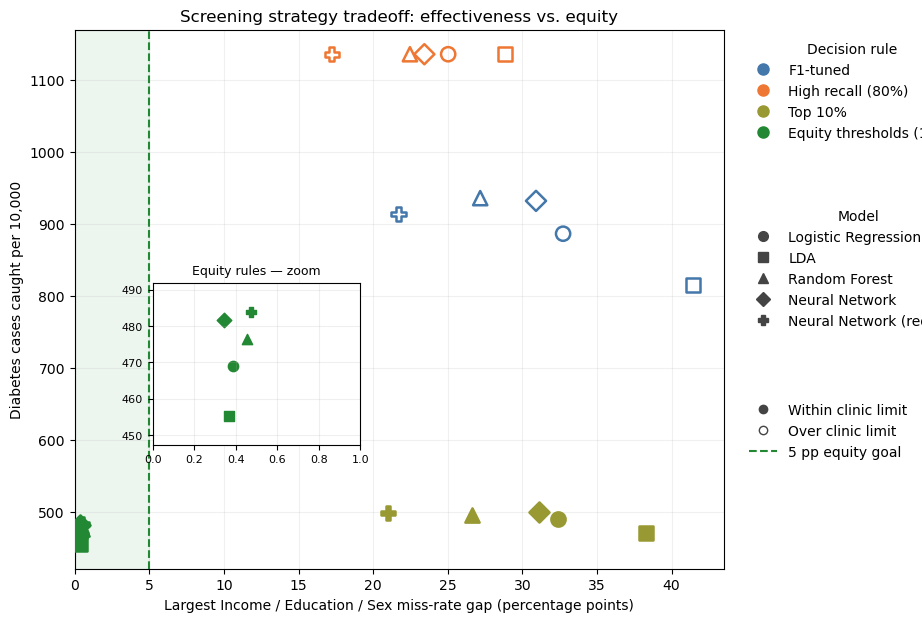

In [16]:
from matplotlib.lines import Line2D

strategy_colors = dict(zip(STRATEGIES, ['#4477AA', '#EE7733', '#999933', '#228833']))
model_names = [entry['Model'] for entry in model_registry]
model_markers = dict(zip(model_names, ['o', 's', '^', 'D', 'P']))
model_labels = {name: name.replace(' (without Income/Education/Sex)', ' (reduced)') for name in model_names}

fig, ax = plt.subplots(figsize=(11, 7))
ax.axvspan(0, EQUITY_TARGET_PP, color='#228833', alpha=0.08)
ax.axvline(EQUITY_TARGET_PP, color='#228833', linestyle='--', linewidth=1.5)
for _, row in strategy_results.iterrows():
    color = strategy_colors[row['Strategy']]
    ax.scatter(row['largest_gap_pp'], row['cases_caught_per_10000'],
               marker=model_markers[row['Model']], s=105, edgecolors=color,
               facecolors=color if row['capacity_met'] else 'none', linewidths=1.8, zorder=3)
ax.set(xlabel='Largest Income / Education / Sex miss-rate gap (percentage points)',
       ylabel='Diabetes cases caught per 10,000',
       title='Screening strategy tradeoff: effectiveness vs. equity')
ax.set_xlim(left=0)
ax.grid(alpha=0.18)
strategy_handles = [Line2D([0], [0], marker='o', color=color, label=s, linestyle='none',
                           markersize=8) for s, color in strategy_colors.items()]
model_handles = [Line2D([0], [0], marker=marker, color='#444444', label=model_labels[name],
                        linestyle='none', markersize=7) for name, marker in model_markers.items()]
capacity_handles = [Line2D([0], [0], marker='o', color='#444444', linestyle='none', label='Within clinic limit'),
                    Line2D([0], [0], marker='o', color='#444444', markerfacecolor='none',
                           linestyle='none', label='Over clinic limit'),
                    Line2D([0], [0], color='#228833', linestyle='--', label='5 pp equity goal')]
legend1 = ax.legend(handles=strategy_handles, title='Decision rule', loc='upper left',
                    bbox_to_anchor=(1.02, 1.0), frameon=False)
ax.add_artist(legend1)
legend2 = ax.legend(handles=model_handles, title='Model', loc='upper left',
                    bbox_to_anchor=(1.02, 0.69), frameon=False)
ax.add_artist(legend2)
ax.legend(handles=capacity_handles, loc='upper left', bbox_to_anchor=(1.02, 0.33), frameon=False)
zoom = ax.inset_axes([0.12, 0.23, 0.32, 0.30])
zoom_fair = strategy_results.loc[strategy_results['Strategy'] == STRATEGIES[3]]
for _, row in zoom_fair.iterrows():
    zoom.scatter(row['largest_gap_pp'], row['cases_caught_per_10000'],
                 marker=model_markers[row['Model']], color=strategy_colors[STRATEGIES[3]], s=55)
zoom.set_xlim(0, max(1.0, zoom_fair['largest_gap_pp'].max() * 1.2))
zoom.set_ylim(zoom_fair['cases_caught_per_10000'].min() - 8, zoom_fair['cases_caught_per_10000'].max() + 8)
zoom.set_title('Equity rules — zoom', fontsize=9)
zoom.tick_params(labelsize=8)
zoom.grid(alpha=0.2)
fig.subplots_adjust(left=0.10, right=0.69, bottom=0.13, top=0.90)
plt.show()

### 3.4 Quantify the competing stakeholder priorities

Compare the two capacity-constrained policies directly within each model. A reduction in the gap is an equity gain; fewer cases caught is a detection cost. This isolates the decision-rule tradeoff without assuming additional appointments. The table also shows how many slots the equity cutoffs actually use. The high-recall comparison separately measures what extra screening resources buy.

In [17]:
def strategy_slice(strategy):
    return strategy_results.loc[strategy_results['Strategy'] == strategy].set_index('Model')

base = strategy_slice('F1-tuned')
high = strategy_slice('High recall (80%)')
quota = strategy_slice('Top 10%')
fair = strategy_slice('Equity thresholds (10%)')

capacity_tradeoff = pd.DataFrame({
    'Top 10% flagged': quota['people_flagged_per_10000'],
    'Equity flagged': fair['people_flagged_per_10000'],
    'Top 10% caught': quota['cases_caught_per_10000'],
    'Equity caught': fair['cases_caught_per_10000'],
    'Change in caught (equity - top 10%)': fair['cases_caught_per_10000'] - quota['cases_caught_per_10000'],
    'Top 10% gap (pp)': quota['largest_gap_pp'],
    'Equity gap (pp)': fair['largest_gap_pp'],
    'Gap reduction (pp)': quota['largest_gap_pp'] - fair['largest_gap_pp'],
    'Equity goal met': fair['equity_target_met'],
}).reset_index()
high_recall_tradeoff = pd.DataFrame({
    'Extra appointments vs F1': high['people_flagged_per_10000'] - base['people_flagged_per_10000'],
    'Extra cases caught vs F1': high['cases_caught_per_10000'] - base['cases_caught_per_10000'],
    'Appointments above clinic limit': high['appointments_over_limit_per_10000'],
    'High recall gap (pp)': high['largest_gap_pp'],
    'Gap reduction vs F1 (pp)': base['largest_gap_pp'] - high['largest_gap_pp'],
}).reset_index()
print('Capacity-controlled comparison (per 10,000):')
display(capacity_tradeoff.round(1))
print('High recall vs F1 (per 10,000):')
display(high_recall_tradeoff.round(1))

# Show which attributes account for the disparity, and separate Age from the main target.
attribute_gaps = strategy_gaps.pivot(index=['Model', 'Strategy'], columns='attribute', values='gap_pp')
display(attribute_gaps.reindex(columns=AUDIT_COLUMNS).round(2))

# Small joint groups are more sensitive to score ties and case-count variation.
cutoff_diagnostics = equity_cutoffs.groupby('Model', sort=False).agg(
    joint_groups=('n', 'size'), smallest_group=('n', 'min'),
    smallest_diabetes_count=('n_diabetes', 'min'), min_joint_recall=('recall', 'min'),
    max_joint_recall=('recall', 'max')).reset_index()
cutoff_diagnostics['joint_recall_gap_pp'] = 100 * (cutoff_diagnostics['max_joint_recall'] - cutoff_diagnostics['min_joint_recall'])
print('Joint-group threshold support and achieved recall spread:')
display(cutoff_diagnostics.round(3))

Capacity-controlled comparison (per 10,000):


,Model,Top 10% flagged,Equity flagged,Top 10% caught,Equity caught,Change in caught (equity - top 10%),Top 10% gap (pp),Equity gap (pp),Gap reduction (pp),Equity goal met
0,Logistic Regression,1000.0,999.4,489.9,469.0,-20.9,32.4,0.4,32.0,True
1,LDA,1000.0,999.2,471.0,455.3,-15.7,38.3,0.4,37.9,True
2,Random Forest,1000.0,998.8,495.3,476.4,-18.9,26.6,0.5,26.1,True
3,Neural Network,1000.0,998.4,499.7,481.6,-18.1,31.1,0.3,30.8,True
4,Neural Network (without Income/Education/Sex),1000.0,998.6,498.1,483.8,-14.3,21.0,0.5,20.5,True


High recall vs F1 (per 10,000):


,Model,Extra appointments vs F1,Extra cases caught vs F1,Appointments above clinic limit,High recall gap (pp),Gap reduction vs F1 (pp)
0,Logistic Regression,1357.8,249.1,2700.3,25.0,7.7
1,LDA,1656.7,320.4,2779.0,28.8,12.6
2,Random Forest,1128.5,199.8,2657.5,22.5,4.7
3,Neural Network,1148.2,203.6,2648.5,23.4,7.5
4,Neural Network (without Income/Education/Sex),1233.3,221.6,2665.9,17.2,4.5


attribute                                                              Income_group  \
Model                                         Strategy                                
LDA                                           Equity thresholds (10%)          0.17   
                                              F1-tuned                        41.42   
                                              High recall (80%)               28.83   
                                              Top 10%                         38.31   
Logistic Regression                           Equity thresholds (10%)          0.13   
                                              F1-tuned                        32.72   
                                              High recall (80%)               25.02   
                                              Top 10%                         32.40   
Neural Network                                Equity thresholds (10%)          0.22   
                                              F1-tuned                        30.91   
                                              High recall (80%)               23.43   
                                              Top 10%                         31.13   
Neural Network (without Income/Education/Sex) Equity thresholds (10%)          0.13   
                                              F1-tuned                        21.69   
                                              High recall (80%)               17.23   
                                              Top 10%                         20.98   
Random Forest                                 Equity thresholds (10%)          0.17   
                                              F1-tuned                        27.17   
                                              High recall (80%)               22.46   
                                              Top 10%                         26.59   

attribute                                                              Education_group  \
Model                                         Strategy                                   
LDA                                           Equity thresholds (10%)             0.37   
                                              F1-tuned                           31.07   
                                              High recall (80%)                  17.92   
                                              Top 10%                            33.27   
Logistic Regression                           Equity thresholds (10%)             0.39   
                                              F1-tuned                           20.47   
                                              High recall (80%)                  14.21   
                                              Top 10%                            22.75   
Neural Network                                Equity thresholds (10%)             0.34   
                                              F1-tuned                           20.41   
                                              High recall (80%)                  14.90   
                                              Top 10%                            19.76   
Neural Network (without Income/Education/Sex) Equity thresholds (10%)             0.48   
                                              F1-tuned                           13.41   
                                              High recall (80%)                  10.94   
                                              Top 10%                            12.83   
Random Forest                                 Equity thresholds (10%)             0.46   
                                              F1-tuned                           18.00   
                                              High recall (80%)                  12.80   
                                              Top 10%                            16.39   

attribute                                                              Sex_group  \
Model               

Joint-group threshold support and achieved recall spread:


,Model,joint_groups,smallest_group,smallest_diabetes_count,min_joint_recall,max_joint_recall,joint_recall_gap_pp
0,Logistic Regression,24,44,6,0.329,0.375,4.569
1,LDA,24,44,6,0.319,0.375,5.567
2,Random Forest,24,44,6,0.334,0.500,16.590
3,Neural Network,24,44,6,0.338,0.500,16.193
4,Neural Network (without Income/Education/Sex),24,44,6,0.339,0.500,16.094


### 3.5 Validation interpretation and handoff

The following summary identifies the strongest capacity-constrained choices without locking in the final recommendation. Among candidates satisfying both stakeholder targets, prioritize cases caught; if none satisfy both, show the smallest-gap capacity-constrained strategy as an alternative. The highest-detection feasible option may have a larger gap. Do not treat validation equity estimates as guaranteed deployment performance.

In [18]:
capacity_options = strategy_results.loc[strategy_results['capacity_met']].copy()
both_targets = capacity_options.loc[capacity_options['equity_target_met']]
max_detection = capacity_options.sort_values(['cases_caught_per_10000', 'largest_gap_pp'], ascending=[False, True]).iloc[0]
if len(both_targets):
    equity_candidate = both_targets.sort_values(['cases_caught_per_10000', 'largest_gap_pp'], ascending=[False, True]).iloc[0]
    print('Best detection among options meeting both validation goals:')
else:
    equity_candidate = capacity_options.sort_values(['largest_gap_pp', 'cases_caught_per_10000'], ascending=[True, False]).iloc[0]
    print('No option meets both goals. Smallest-gap option within clinic capacity:')


def describe_option(row):
    return (f"{row['Model']} — {row['Strategy']}: {row['people_flagged_per_10000']:,.1f} flagged, "
            f"{row['cases_caught_per_10000']:,.1f} caught, {row['cases_missed_per_10000']:,.1f} missed per 10,000; "
            f"{row['largest_gap_pp']:.2f} pp largest gap; {row['precision']:.1%} precision.")

print(describe_option(equity_candidate))
print('Highest detection within clinic capacity:')
print(describe_option(max_detection))
print(f"Equity-oriented choice versus highest detection: "
      f"{max_detection['largest_gap_pp'] - equity_candidate['largest_gap_pp']:.2f} pp smaller gap; "
      f"{max_detection['cases_caught_per_10000'] - equity_candidate['cases_caught_per_10000']:.1f} fewer cases caught per 10,000.")

# Group-level results for the equity-oriented candidate, ready for uncertainty analysis.
candidate_key = (equity_candidate['Model'], equity_candidate['Strategy'])
candidate_groups = decision_evaluations[candidate_key]['by_group']
display(candidate_groups[['attribute', 'group', 'n_diabetes', 'miss_rate', 'recall', 'precision']].round(4))

Best detection among options meeting both validation goals:
Neural Network (without Income/Education/Sex) — Equity thresholds (10%): 998.6 flagged, 483.8 caught, 935.4 missed per 10,000; 0.48 pp largest gap; 48.5% precision.
Highest detection within clinic capacity:
Neural Network — Top 10%: 1,000.0 flagged, 499.7 caught, 919.5 missed per 10,000; 31.13 pp largest gap; 50.0% precision.
Equity-oriented choice versus highest detection: 30.66 pp smaller gap; 15.9 fewer cases caught per 10,000.


,attribute,group,n_diabetes,miss_rate,recall,precision
0,Income_group,"< $25,000",2668,0.6597,0.3403,0.5516
1,Income_group,"$25,000–< $50,000",1892,0.6591,0.3409,0.4799
2,Income_group,"$50,000–< $75,000",1066,0.6585,0.3415,0.4527
3,Income_group,"$75,000+",1443,0.6584,0.3416,0.4178
4,Education_group,Below high school,719,0.6551,0.3449,0.5299
5,Education_group,High school graduate,2255,0.6590,0.3410,0.5029
6,Education_group,Postsecondary attendance,4095,0.6598,0.3402,0.4679
7,Sex_group,Female,3713,0.6596,0.3404,0.4790
8,Sex_group,Male,3356,0.6585,0.3415,0.4908
9,Age_group,65+,3648,0.6456,0.3544,0.4830


### Fairness and uncertainty

For every model and decision strategy, report each group's miss rate (false negatives divided by actual diabetes cases) with a 95% percentile bootstrap interval. The bootstrap resamples observed missed/not-missed outcomes among actual cases within each group. It holds validation predictions and thresholds fixed, so the intervals describe case-sampling uncertainty, not uncertainty from model fitting or strategy selection. The largest Income/Education/Sex gap determines whether the five-percentage-point target holds; Age is reported separately under the current project definition.

The most overlooked group is the group with the highest miss rate within each attribute. We also show the lowest-miss group and the within-attribute gap. Comparisons are validation-only and exploratory until confirmed on the untouched test split.

The input-ablation comparison removes Income, Education, and Sex from the model features. The equity-threshold strategy still uses these group labels to assign cutoffs, so that comparison is not a fully group-blind decision policy.

In [19]:
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 20261120
bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_rows, overlooked_rows, target_rows = [], [], []
miss_rate_ci_lookup = {}
primary_audit_columns = [c for c in AUDIT_COLUMNS if c not in ('Age', 'Age_group')]

for key, result in decision_evaluations.items():
    model_name, strategy = key
    rule_info = decision_rules[key]
    probability_column = rule_info['probability_column']
    rule = {k: v for k, v in rule_info.items() if k != 'probability_column'}
    predicted = apply_decision_rule(part3_val, probability_column, rule).to_numpy()
    actual = part3_y.to_numpy()

    for attribute in AUDIT_COLUMNS:
        labels = part3_groups[attribute].astype(str).to_numpy()
        attribute_rows = result['by_group'].loc[result['by_group']['attribute'] == attribute]
        for group in pd.unique(labels):
            in_group = labels == group
            positive = in_group & (actual == 1)
            n_diabetes = int(positive.sum())
            if n_diabetes == 0:
                raise ValueError(f'No validation cases for {attribute}={group}; miss rate is undefined.')
            missed = int((predicted[positive] == 0).sum())
            miss_rate = missed / n_diabetes
            bootstrap_rates = bootstrap_rng.binomial(
                n=n_diabetes, p=miss_rate, size=BOOTSTRAP_REPLICATES
            ) / n_diabetes
            ci_low, ci_high = np.quantile(bootstrap_rates, [0.025, 0.975])
            miss_rate_ci_lookup[(model_name, strategy, attribute, group)] = (
                float(ci_low), float(ci_high)
            )
            bootstrap_rows.append({
                'Model': model_name, 'Strategy': strategy, 'attribute': attribute,
                'group': group, 'n_diabetes': n_diabetes, 'miss_rate': miss_rate,
                'miss_rate_ci_low': float(ci_low), 'miss_rate_ci_high': float(ci_high),
            })

        rates = attribute_rows.set_index('group')['miss_rate']
        worst_group, best_group = rates.idxmax(), rates.idxmin()
        worst, best = rates.loc[worst_group], rates.loc[best_group]
        worst_ci = miss_rate_ci_lookup[(model_name, strategy, attribute, worst_group)]
        overlooked_rows.append({
            'Model': model_name, 'Strategy': strategy, 'attribute': attribute,
            'most_overlooked_group': worst_group, 'highest_miss_rate': worst,
            'highest_miss_ci_low': worst_ci[0], 'highest_miss_ci_high': worst_ci[1],
            'lowest_miss_group': best_group, 'lowest_miss_rate': best,
            'within_attribute_gap_pp': 100 * (worst - best),
        })

    gaps = result['gaps'].set_index('attribute')['gap_pp']
    primary_gaps = gaps.reindex(primary_audit_columns).dropna()
    if primary_gaps.empty:
        raise ValueError('No primary demographic miss-rate gaps were available.')
    target_rows.append({
        'Model': model_name, 'Strategy': strategy,
        'largest_primary_gap_pp': float(primary_gaps.max()),
        'attribute_with_largest_gap': primary_gaps.idxmax(),
        'five_point_target_met': bool(primary_gaps.max() <= EQUITY_TARGET_PP + 1e-12),
        'age_gap_pp': float(gaps.get('Age_group', np.nan)),
    })

miss_rate_bootstrap = pd.DataFrame(bootstrap_rows)
strategy_group_with_ci = strategy_by_group.merge(
    miss_rate_bootstrap[['Model', 'Strategy', 'attribute', 'group',
                         'miss_rate_ci_low', 'miss_rate_ci_high']],
    on=['Model', 'Strategy', 'attribute', 'group'], validate='one_to_one'
)
overlooked_by_strategy = pd.DataFrame(overlooked_rows)
five_point_target_by_strategy = pd.DataFrame(target_rows)

print('Group miss rates with 95% bootstrap intervals:')
display(strategy_group_with_ci[
    ['Model', 'Strategy', 'attribute', 'group', 'n_diabetes',
     'miss_rate', 'miss_rate_ci_low', 'miss_rate_ci_high']
].sort_values(['Model', 'Strategy', 'attribute', 'group']).round(4))
print('Most-overlooked groups and within-attribute gaps:')
display(overlooked_by_strategy.sort_values(
    ['Model', 'Strategy', 'attribute']
).round(2))
print('Does the five-percentage-point Income/Education/Sex target hold?')
display(five_point_target_by_strategy.sort_values(
    ['Model', 'Strategy']
).round(2))

# Compare the best full model with its matched input-ablated refit under each strategy.
full_auc = ablation_comparison.set_index('Model').loc[best_model_name, 'ROC AUC']
reduced_auc = ablation_comparison.set_index('Model').loc[reduced_model_name, 'ROC AUC']
ablation_strategy_rows = []
for strategy in STRATEGIES:
    full = strategy_results.loc[
        (strategy_results['Model'] == best_model_name) &
        (strategy_results['Strategy'] == strategy)
    ].iloc[0]
    reduced = strategy_results.loc[
        (strategy_results['Model'] == reduced_model_name) &
        (strategy_results['Strategy'] == strategy)
    ].iloc[0]
    ablation_strategy_rows.append({
        'Strategy': strategy, 'Full model ROC AUC': full_auc,
        'Reduced model ROC AUC': reduced_auc,
        'ROC AUC change': reduced_auc - full_auc,
        'Change in cases caught per 10,000': (
            reduced['cases_caught_per_10000'] - full['cases_caught_per_10000']),
        'Change in largest primary gap (pp)': (
            reduced['largest_gap_pp'] - full['largest_gap_pp']),
        'Change in age gap (pp)': reduced['age_gap_pp'] - full['age_gap_pp'],
        'Full model meets 5 pp': full['equity_target_met'],
        'Reduced model meets 5 pp': reduced['equity_target_met'],
    })
ablation_strategy_comparison = pd.DataFrame(ablation_strategy_rows)
print('Effect of removing Income, Education, and Sex (reduced minus full):')
display(ablation_strategy_comparison.round(3))

Group miss rates with 95% bootstrap intervals:


,Model,Strategy,attribute,group,n_diabetes,miss_rate,miss_rate_ci_low,miss_rate_ci_high
94,LDA,Equity thresholds (10%),Age_group,18–44,452,0.8695,0.8385,0.9004
95,LDA,Equity thresholds (10%),Age_group,45–64,2969,0.6942,0.6780,0.7107
93,LDA,Equity thresholds (10%),Age_group,65+,3648,0.6434,0.6277,0.6587
88,LDA,Equity thresholds (10%),Education_group,Below high school,719,0.6759,0.6412,0.7094
89,LDA,Equity thresholds (10%),Education_group,High school graduate,2255,0.6794,0.6603,0.6985
...,...,...,...,...,...,...,...,...
122,Random Forest,Top 10%,Income_group,"$50,000–< $75,000",1066,0.7317,0.7045,0.7580
123,Random Forest,Top 10%,Income_group,"$75,000+",1443,0.8060,0.7852,0.8267
120,Random Forest,Top 10%,Income_group,"< $25,000",2668,0.5401,0.5206,0.5589
127,Random Forest,Top 10%,Sex_group,Female,3713,0.6429,0.6270,0.6580


Most-overlooked groups and within-attribute gaps:


,Model,Strategy,attribute,most_overlooked_group,highest_miss_rate,highest_miss_ci_low,highest_miss_ci_high,lowest_miss_group,lowest_miss_rate,within_attribute_gap_pp
31,LDA,Equity thresholds (10%),Age_group,18–44,0.87,0.84,0.90,65+,0.64,22.61
29,LDA,Equity thresholds (10%),Education_group,Postsecondary attendance,0.68,0.67,0.69,Below high school,0.68,0.37
28,LDA,Equity thresholds (10%),Income_group,"< $25,000",0.68,0.66,0.70,"$50,000–< $75,000",0.68,0.17
30,LDA,Equity thresholds (10%),Sex_group,Female,0.68,0.66,0.69,Male,0.68,0.02
19,LDA,F1-tuned,Age_group,18–44,0.68,0.64,0.73,65+,0.36,32.04
...,...,...,...,...,...,...,...,...,...,...
38,Random Forest,High recall (80%),Sex_group,Female,0.21,0.19,0.22,Male,0.19,1.12
43,Random Forest,Top 10%,Age_group,18–44,0.88,0.85,0.91,65+,0.63,24.89
41,Random Forest,Top 10%,Education_group,Postsecondary attendance,0.69,0.68,0.71,Below high school,0.53,16.39
40,Random Forest,Top 10%,Income_group,"$75,000+",0.81,0.79,0.83,"< $25,000",0.54,26.59


Does the five-percentage-point Income/Education/Sex target hold?


,Model,Strategy,largest_primary_gap_pp,attribute_with_largest_gap,five_point_target_met,age_gap_pp
7,LDA,Equity thresholds (10%),0.37,Education_group,True,22.61
4,LDA,F1-tuned,41.42,Income_group,False,32.04
5,LDA,High recall (80%),28.83,Income_group,False,32.01
6,LDA,Top 10%,38.31,Income_group,False,21.71
3,Logistic Regression,Equity thresholds (10%),0.39,Education_group,True,27.49
0,Logistic Regression,F1-tuned,32.72,Income_group,False,39.32
1,Logistic Regression,High recall (80%),25.02,Income_group,False,38.15
2,Logistic Regression,Top 10%,32.40,Income_group,False,28.40
15,Neural Network,Equity thresholds (10%),0.34,Education_group,True,22.25
12,Neural Network,F1-tuned,30.91,Income_group,False,34.99


Effect of removing Income, Education, and Sex (reduced minus full):


,Strategy,Full model ROC AUC,Reduced model ROC AUC,ROC AUC change,"Change in cases caught per 10,000",Change in largest primary gap (pp),Change in age gap (pp),Full model meets 5 pp,Reduced model meets 5 pp
0,F1-tuned,0.831,0.831,-0.001,-18.069,-9.218,1.948,False,False
1,High recall (80%),0.831,0.831,-0.001,0.000,-6.199,3.399,False,False
2,Top 10%,0.831,0.831,-0.001,-1.606,-10.151,1.157,False,False
3,Equity thresholds (10%),0.831,0.831,-0.001,2.208,0.132,-0.183,True,True


The equity-threshold strategy is the only one that meets the five-point Income/Education/Sex target for every model: its largest gap is 0.31–0.56 percentage points. F1-tuned, high-recall, and top-10% strategies all miss the target (17.29–41.42 pp); Income is the limiting attribute in each case. This improvement is specific to a group-aware threshold policy and should not be read as evidence that the underlying scores are equally accurate across groups.

Age disparities remain substantial despite meeting the primary target: age gaps range from 20.11 to 39.53 pp. For example, under LDA's equity thresholds the 18–44 group misses 87% of cases (95% CI 83.8–89.8%), versus 64% for ages 65+. Age is therefore reported separately, not treated as resolved by the primary target.

Removing Income, Education, and Sex lowers ROC AUC by only 0.001 and reduces the primary gap under every strategy. For F1-tuned, high-recall, and top-10% decisions, however, the reduced model still exceeds the five-point target (gaps of 21.40, 17.29, and 21.84 pp). Under equity thresholds both versions meet the target; removal narrows the gap by just 0.21 pp and catches about 4.8 fewer cases per 10,000. The result is a modest fairness improvement for most strategies, not a stand-alone solution. Bootstrap intervals describe subgroup miss-rate uncertainty with predictions held fixed; they do not capture model/threshold selection uncertainty or directly test differences between groups.

### Position on Age

Retain Age as a predictor provisionally: age is clinically relevant to diabetes risk, and removing it solely because it is demographic could discard useful signal without correcting disparities caused by correlated predictors. This is not a blanket exemption. Report age-group miss rates and intervals alongside the primary audit, investigate any large age gap, and revisit the decision if clinical review, policy, or age-specific harm evidence changes the balance. Under the current project definition, the five-point target applies to Income, Education, and Sex—not Age—so passing it must not be presented as evidence that age disparities are acceptable. The reduced-input model also retains Age, so this notebook does not test the effect of removing Age.

**Limitations and next steps.** The equity thresholds are fitted on validation labels; measured validation gaps are optimistic by construction and should be checked on an untouched test sample only after the team selects the final model and rule. A fixed common or joint-group threshold may flag more or fewer than 10% on new data; if the clinic limit is non-negotiable, a separate capacity enforcement rule must be specified and validated before testing. The top-10% rule naturally enforces the quota. The reduced model excludes Income, Education and Sex from its score inputs, but its equity-threshold policy still requires those attributes for decisions. Group-specific thresholds are a hypothetical policy, not a clinical deployment recommendation; appropriateness, privacy, and operational feasibility require review. The 2015 cross-sectional survey and self-reported labels do not establish prospective screening effectiveness.

## Part 5 — Final test-set evaluation

Everything above was chosen on the **validation** split. Here we apply the rules exactly as they were frozen there (the same F1 and high-recall cutoffs, the same 10% quota and the same joint-group equity cutoffs) to the **untouched test split, once**. Nothing is refit or retuned on test data.

- **Recommended strategy:** Neural Network with equity thresholds (10%).
- **Main comparison:** Neural Network with the top 10% rule, which gave the highest detection within clinic capacity.
- **Capacity check:** fixed equity cutoffs can flag more or fewer than 1,000 per 10,000 on new data. Part 5.2 applies a pre-specified cap rule and reports both versions.
- **Uncertainty:** Part 5.3 bootstraps people in the test set to give 95% intervals for each group's miss rate and for the largest gap.

In [20]:
# 5.1 Apply every validation-frozen rule to the untouched test split.
RECOMMENDED = ('Neural Network', 'Equity thresholds (10%)')
COMPARATOR = ('Neural Network', 'Top 10%')

part5_test = test_predictions.set_index('row_id', verify_integrity=True)
part5_y = (test_labels.set_index('row_id', verify_integrity=True)['y_actual']
           .reindex(part5_test.index))
assert part5_y.notna().all(), 'Test labels do not align with test predictions.'
part5_y = part5_y.astype(int)
part5_groups = part5_test[AUDIT_COLUMNS]
test_quota = int(np.floor(len(part5_test) * SCREENING_FRACTION))
assert RECOMMENDED in decision_rules and COMPARATOR in decision_rules


def test_summary_row(model, strategy, predicted, result):
    row = result['overall'].iloc[0]
    return {'Model': model, 'Strategy': strategy,
            'Flagged per 10k': row['people_flagged_per_10000'],
            'Caught per 10k': row['cases_caught_per_10000'],
            'Missed per 10k': row['cases_missed_per_10000'],
            'Recall': row['recall'], 'Precision': row['precision'],
            'Largest gap (pp)': result['largest_gap_pp'],
            'Age gap (pp)': result['age_gap'] * 100,
            'Equity goal met': result['equity_target_met'],
            'Clinic limit met': int(predicted.sum()) <= test_quota}


test_evaluations, test_rows = {}, []
for key, rule_info in decision_rules.items():
    column = rule_info['probability_column']
    rule = {k: v for k, v in rule_info.items() if k != 'probability_column'}
    predicted = apply_decision_rule(part5_test, column, rule)
    result = evaluate(part5_groups, part5_y, predicted)
    test_evaluations[key] = (predicted, result)
    test_rows.append(test_summary_row(key[0], key[1], predicted, result))

test_results = pd.DataFrame(test_rows)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)
print(f'Test split: {len(part5_test):,} people, {int(part5_y.sum()):,} with diabetes; '
      f'clinic quota = {test_quota:,} appointments (1,000 per 10,000).')
display(test_results.round(3))

Test split: 49,810 people, 7,069 with diabetes; clinic quota = 4,981 appointments (1,000 per 10,000).


,Model,Strategy,Flagged per 10k,Caught per 10k,Missed per 10k,Recall,Precision,Largest gap (pp),Age gap (pp),Equity goal met,Clinic limit met
0,Logistic Regression,F1-tuned,2355.953,900.020,519.173,0.634,0.382,37.773,38.697,False,False
1,Logistic Regression,High recall (80%),3697.450,1140.534,278.659,0.804,0.308,27.566,39.037,False,False
2,Logistic Regression,Top 10%,1000.000,483.437,935.756,0.341,0.483,36.480,28.427,False,True
3,Logistic Regression,Equity thresholds (10%),1004.618,461.955,957.238,0.326,0.460,5.299,26.659,False,False
4,LDA,F1-tuned,2108.813,816.302,602.891,0.575,0.387,49.092,30.423,False,False
5,LDA,High recall (80%),3775.748,1137.723,281.470,0.802,0.301,31.900,31.248,False,False
6,LDA,Top 10%,1000.000,465.971,953.222,0.328,0.466,41.908,19.333,False,True
7,LDA,Equity thresholds (10%),988.958,444.891,974.302,0.313,0.450,7.605,20.724,False,True
8,Random Forest,F1-tuned,2547.280,942.381,476.812,0.664,0.370,30.612,38.777,False,False
9,Random Forest,High recall (80%),3661.313,1137.322,281.871,0.801,0.311,24.686,38.901,False,False


In [21]:
# 5.2 Capacity enforcement for the equity rule (specified before looking at test results).
# If the frozen cutoffs flag more than the quota, every joint group keeps the same share
# of its flagged people (highest scores first); leftover slots go to the highest scores overall.
def enforce_capacity(frame, probability_column, rule, fraction=SCREENING_FRACTION):
    predicted = apply_decision_rule(frame, probability_column, rule)
    quota = int(np.floor(len(frame) * fraction))
    if int(predicted.sum()) <= quota:
        return predicted
    scores = frame[probability_column]
    keys = equity_keys(frame)
    share = quota / int(predicted.sum())
    keep = []
    for _, idx in keys[predicted == 1].groupby(keys[predicted == 1], sort=False).groups.items():
        ranked = scores.loc[idx].sort_values(ascending=False, kind='mergesort').index
        keep.extend(ranked[:int(np.floor(share * len(ranked)))])
    remaining = scores.loc[predicted[predicted == 1].index.difference(keep)]
    keep.extend(remaining.sort_values(ascending=False, kind='mergesort')
                .index[:quota - len(keep)])
    capped = pd.Series(0, index=frame.index, dtype='int8', name='y_pred')
    capped.loc[keep] = 1
    return capped


rec_info = decision_rules[RECOMMENDED]
rec_rule = {k: v for k, v in rec_info.items() if k != 'probability_column'}
capped_pred = enforce_capacity(part5_test, rec_info['probability_column'], rec_rule)
capped_result = evaluate(part5_groups, part5_y, capped_pred)
assert int(capped_pred.sum()) <= test_quota

uncapped_flagged = int(test_evaluations[RECOMMENDED][0].sum())
print(f'Frozen equity cutoffs flag {uncapped_flagged:,} people on test '
      f'({uncapped_flagged / len(part5_test) * 10000:,.1f} per 10,000) against a quota of {test_quota:,}.')
if uncapped_flagged > test_quota:
    print('Over the clinic limit, so the capped version below is the deployable rule.')
else:
    print('Within the clinic limit, so the cap changes nothing.')

capacity_table = pd.DataFrame([
    test_summary_row(*RECOMMENDED, *test_evaluations[RECOMMENDED]),
    test_summary_row(RECOMMENDED[0], 'Equity thresholds (10%), capped', capped_pred, capped_result),
    test_summary_row(*COMPARATOR, *test_evaluations[COMPARATOR]),
])
display(capacity_table.round(3))

Frozen equity cutoffs flag 4,981 people on test (1,000.0 per 10,000) against a quota of 4,981.
Within the clinic limit, so the cap changes nothing.


,Model,Strategy,Flagged per 10k,Caught per 10k,Missed per 10k,Recall,Precision,Largest gap (pp),Age gap (pp),Equity goal met,Clinic limit met
0,Neural Network,Equity thresholds (10%),1000.0,468.581,950.612,0.330,0.469,6.180,21.021,False,True
1,Neural Network,"Equity thresholds (10%), capped",1000.0,468.581,950.612,0.330,0.469,6.180,21.021,False,True
2,Neural Network,Top 10%,1000.0,499.297,919.896,0.352,0.499,33.525,20.961,False,True


In [22]:
# 5.3 Bootstrap uncertainty on the test split: resample people with replacement.
# Each replicate recomputes every group's miss rate and the largest Income/Education/Sex gap.
# Predictions stay fixed, so intervals reflect who happened to be in the test sample.
TEST_BOOTSTRAP_REPLICATES = 2000


def bootstrap_test(groups, y, pred, reps=TEST_BOOTSTRAP_REPLICATES, seed=20261122):
    rng = np.random.default_rng(seed)
    y, pred = np.asarray(y), np.asarray(pred)
    n = len(y)
    coded = {a: pd.factorize(groups[a].astype(str)) for a in AUDIT_COLUMNS}
    rates = {a: np.full((reps, len(labels)), np.nan) for a, (_, labels) in coded.items()}
    largest = np.empty(reps)
    for r in range(reps):
        idx = rng.integers(0, n, n)
        pos = y[idx] == 1
        missed = pos & (pred[idx] == 0)
        for a, (codes, labels) in coded.items():
            c = codes[idx]
            cases = np.bincount(c[pos], minlength=len(labels))
            misses = np.bincount(c[missed], minlength=len(labels))
            with np.errstate(invalid='ignore', divide='ignore'):
                rates[a][r] = misses / cases
        largest[r] = max(100 * (np.nanmax(rates[a][r]) - np.nanmin(rates[a][r]))
                         for a in EQUITY_COLUMNS)
    group_rows = []
    for a, (_, labels) in coded.items():
        low, high = np.nanquantile(rates[a], [0.025, 0.975], axis=0)
        for j, label in enumerate(labels):
            group_rows.append({'attribute': a, 'group': label,
                               'miss_rate_ci_low': low[j], 'miss_rate_ci_high': high[j]})
    return pd.DataFrame(group_rows), np.quantile(largest, [0.025, 0.975])


final_options = {
    'Recommended: equity thresholds' + (', capped' if uncapped_flagged > test_quota else ''):
        capped_pred if uncapped_flagged > test_quota else test_evaluations[RECOMMENDED][0],
    'Comparison: top 10%': test_evaluations[COMPARATOR][0],
}
test_group_tables, gap_interval_rows = [], []
for label, predicted in final_options.items():
    result = evaluate(part5_groups, part5_y, predicted)
    ci_groups, gap_ci = bootstrap_test(part5_groups, part5_y, predicted)
    table = result['by_group'][['attribute', 'group', 'n_diabetes', 'miss_rate']].merge(
        ci_groups, on=['attribute', 'group'], validate='one_to_one')
    test_group_tables.append(table.assign(Option=label))
    gap_interval_rows.append({'Option': label, 'Largest gap (pp)': result['largest_gap_pp'],
                              'Gap 95% CI low': gap_ci[0], 'Gap 95% CI high': gap_ci[1],
                              'Age gap (pp)': result['age_gap'] * 100})

test_group_ci = pd.concat(test_group_tables, ignore_index=True)
print('Miss rate by group on the test split, with 95% bootstrap intervals:')
print(test_group_ci[['Option', 'attribute', 'group', 'n_diabetes', 'miss_rate',
                     'miss_rate_ci_low', 'miss_rate_ci_high']].round(3).to_string(index=False))
print('\nLargest Income/Education/Sex gap with 95% bootstrap interval:')
display(pd.DataFrame(gap_interval_rows).round(2))

Miss rate by group on the test split, with 95% bootstrap intervals:
                        Option       attribute                    group  n_diabetes  miss_rate  miss_rate_ci_low  miss_rate_ci_high
Recommended: equity thresholds    Income_group        $25,000–< $50,000        1943      0.676             0.656              0.697
Recommended: equity thresholds    Income_group        $50,000–< $75,000        1039      0.677             0.647              0.706
Recommended: equity thresholds    Income_group                 $75,000+        1412      0.683             0.659              0.708
Recommended: equity thresholds    Income_group                < $25,000        2675      0.655             0.638              0.674
Recommended: equity thresholds Education_group Postsecondary attendance        4151      0.682             0.668              0.697
Recommended: equity thresholds Education_group     High school graduate        2222      0.662             0.642              0.681
Recommen

,Option,Largest gap (pp),Gap 95% CI low,Gap 95% CI high,Age gap (pp)
0,Recommended: equity thresholds,6.18,3.03,10.00,21.02
1,Comparison: top 10%,33.53,30.75,36.06,20.96


In [23]:
# 5.4 Validation versus test for the final options, and the equity rule across models.
validation_lookup = strategy_results.set_index(['Model', 'Strategy'])
test_lookup = test_results.set_index(['Model', 'Strategy'])
compare_rows = []
for key, label in [(RECOMMENDED, 'Recommended'), (COMPARATOR, 'Comparison')]:
    v = validation_lookup.loc[key]
    t = test_lookup.loc[key]
    compare_rows.append({'Option': f'{label}: {key[0]}, {key[1]}',
                         'Val caught per 10k': v['cases_caught_per_10000'],
                         'Test caught per 10k': t['Caught per 10k'],
                         'Val flagged per 10k': v['people_flagged_per_10000'],
                         'Test flagged per 10k': t['Flagged per 10k'],
                         'Val gap (pp)': v['largest_gap_pp'], 'Test gap (pp)': t['Largest gap (pp)']})
print('Validation versus test:')
display(pd.DataFrame(compare_rows).round(2))

print('Equity thresholds on the test split, by model (supports the model choice):')
display(test_results.loc[test_results['Strategy'] == 'Equity thresholds (10%)']
        .sort_values('Caught per 10k', ascending=False).round(3))

rec = capacity_table.iloc[1] if uncapped_flagged > test_quota else capacity_table.iloc[0]
cmp_ = capacity_table.iloc[2]
gap_row = gap_interval_rows[0]
print('Final test-set summary (per 10,000 people):')
print(f"  Recommended rule: {rec['Flagged per 10k']:,.0f} screened, {rec['Caught per 10k']:,.1f} caught, "
      f"{rec['Missed per 10k']:,.1f} missed; precision {rec['Precision']:.1%}.")
print(f"  Largest Income/Education/Sex gap: {gap_row['Largest gap (pp)']:.2f} pp "
      f"(95% CI {gap_row['Gap 95% CI low']:.2f}–{gap_row['Gap 95% CI high']:.2f}); "
      f"5-point target met: {gap_row['Largest gap (pp)'] <= EQUITY_TARGET_PP}.")
print(f"  Age gap (reported separately): {gap_row['Age gap (pp)']:.1f} pp.")
print(f"  Versus top 10%: {cmp_['Caught per 10k'] - rec['Caught per 10k']:,.1f} fewer cases caught per 10,000 "
      f"for a gap {cmp_['Largest gap (pp)'] - rec['Largest gap (pp)']:.1f} pp smaller.")

Validation versus test:


,Option,Val caught per 10k,Test caught per 10k,Val flagged per 10k,Test flagged per 10k,Val gap (pp),Test gap (pp)
0,"Recommended: Neural Network, Equity thresholds...",481.63,468.58,998.39,1000.0,0.34,6.18
1,"Comparison: Neural Network, Top 10%",499.70,499.30,1000.00,1000.0,31.13,33.53


Equity thresholds on the test split, by model (supports the model choice):


,Model,Strategy,Flagged per 10k,Caught per 10k,Missed per 10k,Recall,Precision,Largest gap (pp),Age gap (pp),Equity goal met,Clinic limit met
19,Neural Network (without Income/Education/Sex),Equity thresholds (10%),1002.610,476.009,943.184,0.335,0.475,7.157,24.120,False,False
11,Random Forest,Equity thresholds (10%),1007.629,470.187,949.006,0.331,0.467,6.866,27.748,False,False
15,Neural Network,Equity thresholds (10%),1000.000,468.581,950.612,0.330,0.469,6.180,21.021,False,True
3,Logistic Regression,Equity thresholds (10%),1004.618,461.955,957.238,0.326,0.460,5.299,26.659,False,False
7,LDA,Equity thresholds (10%),988.958,444.891,974.302,0.313,0.450,7.605,20.724,False,True


Final test-set summary (per 10,000 people):
  Recommended rule: 1,000 screened, 468.6 caught, 950.6 missed; precision 46.9%.
  Largest Income/Education/Sex gap: 6.18 pp (95% CI 3.03–10.00); 5-point target met: False.
  Age gap (reported separately): 21.0 pp.
  Versus top 10%: 30.7 fewer cases caught per 10,000 for a gap 27.3 pp smaller.
